# 🧪 External Validation — VGG-16 Brain Tumor Classifier on BRISC 2025

**Add these 3 inputs (right panel → Add Input) before running:**
1. **BRISC 2025** dataset (the external set, ~6,000 images)
2. **Brain Tumor MRI Dataset** (Masoud Nickparvar) — your training data, used *only* for the duplicate/leakage check
3. **Your trained model** (`best_vgg16_model.h5`) uploaded as a Kaggle Dataset / Model, or notebook output

**Rules for a valid external validation:** the model is only *evaluated* here — no retraining, no threshold tuning, no preprocessing changes based on BRISC results.

Run top to bottom. Everything is saved to `/kaggle/working/external_validation/`.

## Cell 1 — Imports & configuration

In [ ]:
import os, gc, json, warnings, random, subprocess, sys
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tqdm.auto import tqdm
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocess
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, roc_auc_score, roc_curve)
from statsmodels.stats.proportion import proportion_confint

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ── Must match training ──
CLASSES  = ['glioma', 'meningioma', 'notumor', 'pituitary']
IMG_SIZE = 224
BATCH    = 32
N_WORKERS = 4

# ── Reference: internal test accuracy from training notebook ──
INTERNAL_TEST_ACC = 0.9606

OUT_DIR = '/kaggle/working/external_validation'
os.makedirs(OUT_DIR, exist_ok=True)

# ── Optional manual overrides (leave None to auto-detect) ──
MODEL_PATH  = None      # e.g. '/kaggle/input/my-vgg16/best_vgg16_model.h5'
BRISC_ROOT  = None      # e.g. '/kaggle/input/brisc2025'
NICK_ROOT   = None      # folder containing Training/ and Testing/

RUN_DEDUP_CHECK         = True
DEDUP_HAMMING_THRESHOLD = 4     # pHash Hamming distance <= this => near-duplicate

print("TF", tf.__version__, "| GPUs:", len(tf.config.list_physical_devices('GPU')))

TF 2.20.0 | GPUs: 2


## Cell 2 — Auto-detect inputs (model, Nickparvar data)

In [ ]:
INPUT = '/kaggle/input'

# Nickparvar training dataset (folder with Training/ and Testing/)
if NICK_ROOT is None:
    for root, dirs, _ in os.walk(INPUT):
        if 'Training' in dirs and 'Testing' in dirs:
            NICK_ROOT = root
            break
print("Nickparvar root :", NICK_ROOT)

# Model file
if MODEL_PATH is None:
    cands = [str(p) for p in Path(INPUT).rglob('*') if p.suffix.lower() in ('.h5', '.keras')]
    cands = [c for c in cands if 'phase1' not in c.lower()]
    preferred = [c for c in cands if 'vgg' in c.lower() or 'best' in c.lower()]
    cands = preferred or cands
    if not cands:
        raise FileNotFoundError("No .h5/.keras model found under /kaggle/input. Add your model as an input "
                                "or set MODEL_PATH manually.")
    MODEL_PATH = cands[0]
    if len(cands) > 1:
        print("Other model files found:", cands[1:])
print("Model file      :", MODEL_PATH)

Nickparvar root : /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset
Model file      : /kaggle/input/datasets/atharvsadavarte/vgg-16/best_vgg16_model.h5


## Cell 3 — Preprocessing (identical to training pipeline)

In [ ]:
class AdvancedPreprocessor:
    # Same pipeline as training. CLAHE object is created per call so the
    # class is thread-safe (results are identical).
    def __init__(self, clahe_clip=3.0, clahe_tile=(8, 8)):
        self.clahe_clip, self.clahe_tile = clahe_clip, clahe_tile

    def _skull_strip_proxy(self, g):
        b = cv2.GaussianBlur(g, (5, 5), 0)
        _, t = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
        t = cv2.morphologyEx(t, cv2.MORPH_CLOSE, k, iterations=3)
        t = cv2.morphologyEx(t, cv2.MORPH_OPEN,  k, iterations=1)
        cnts, _ = cv2.findContours(t, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if len(cnts) == 0:
            return g
        m = np.zeros_like(g)
        cv2.drawContours(m, [max(cnts, key=cv2.contourArea)], -1, 255, thickness=cv2.FILLED)
        return cv2.bitwise_and(g, g, mask=m)

    def _smart_roi_crop(self, g):
        _, t = cv2.threshold(g, 10, 255, cv2.THRESH_BINARY)
        c = cv2.findNonZero(t)
        if c is None:
            return g
        x, y, w, h = cv2.boundingRect(c)
        px, py = int(w * 0.05), int(h * 0.05)
        H, W = g.shape
        return g[max(0, y - py):min(H, y + h + py), max(0, x - px):min(W, x + w + px)]

    def _apply_clahe(self, g):
        return cv2.createCLAHE(clipLimit=self.clahe_clip, tileGridSize=self.clahe_tile).apply(g)

    def preprocess(self, path):
        img = cv2.imread(str(path))
        if img is None:
            raise ValueError(f"Cannot read image: {path}")
        gray = cv2.cvtColor(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cv2.COLOR_RGB2GRAY)
        x = self._smart_roi_crop(self._skull_strip_proxy(gray))
        x = self._apply_clahe(x)
        x = np.power(x.astype(np.float32) / 255.0, 1.1)
        x = cv2.GaussianBlur((x * 255).astype(np.uint8), (3, 3), sigmaX=1)
        x = cv2.resize(x, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LANCZOS4)
        x = cv2.cvtColor(x, cv2.COLOR_GRAY2RGB).astype(np.float32) / 255.0
        x = (x - x.min()) / (x.max() - x.min() + 1e-8)
        return x

pre = AdvancedPreprocessor()

def prep_for_model(path):
    # preprocess -> uint8 -> VGG-16 mean subtraction (exactly as the training generator did)
    img = pre.preprocess(path)
    return vgg16_preprocess((img * 255).astype(np.uint8).astype(np.float32))

print("✅ Preprocessor ready")

✅ Preprocessor ready


## Cell 4 — Load BRISC 2025 images & labels

In [ ]:
LABEL_MAP = {'glioma': 'glioma', 'meningioma': 'meningioma', 'pituitary': 'pituitary',
             'no_tumor': 'notumor', 'notumor': 'notumor', 'no tumor': 'notumor'}
EXTS = ('.jpg', '.jpeg', '.png', '.tif', '.tiff')

search_root = Path(BRISC_ROOT) if BRISC_ROOT else Path(INPUT)
rows = []
for p in search_root.rglob('*'):
    if p.suffix.lower() not in EXTS or p.parent.name.lower() not in LABEL_MAP:
        continue
    # never pick up the Nickparvar training images
    if NICK_ROOT and BRISC_ROOT is None and str(p).startswith(str(NICK_ROOT)):
        continue
    parts = [x.lower() for x in p.parts]
    split = 'train' if any(x in ('train', 'training') for x in parts) else \
            ('test' if any(x in ('test', 'testing') for x in parts) else 'unknown')
    rows.append({'path': str(p), 'label': LABEL_MAP[p.parent.name.lower()], 'split': split})

df = pd.DataFrame(rows)
# BRISC also ships a segmentation task; keep only the classification folders if present
mask = df['path'].str.lower().str.contains('classification')
if mask.any():
    df = df[mask]
df = df.drop_duplicates('path').sort_values('path').reset_index(drop=True)

print("Total BRISC images:", len(df), "(expected ≈ 6000)")
print("\nBy split:\n", df['split'].value_counts().to_string())
print("\nBy class:\n", df['label'].value_counts().to_string())
print("\nSplit x class:\n", pd.crosstab(df['split'], df['label']))
assert df['label'].nunique() == 4, "Expected 4 classes - check folder names / BRISC_ROOT"
print("\nExample path:", df['path'].iloc[0])

Total BRISC images: 6000 (expected ≈ 6000)

By split:
 split
train    5000
test     1000

By class:
 label
pituitary     1757
meningioma    1635
glioma        1401
notumor       1207

Split x class:
 label  glioma  meningioma  notumor  pituitary
split                                        
test      254         306      140        300
train    1147        1329     1067       1457

Example path: /kaggle/input/datasets/briscdataset/brisc2025/brisc2025/classification_task/test/glioma/brisc2025_test_00001_gl_ax_t1.jpg


## Cell 6 — Load your trained model

In [ ]:
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.applications import VGG16

def build_vgg16_for_weights():
    # Same architecture as training (used only if .h5 loading fails due to a Keras version mismatch)
    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='input_image')
    base = VGG16(include_top=False, weights=None, input_tensor=inputs)
    x = base.output
    se = layers.GlobalAveragePooling2D(name='se_gap')(x)
    se = layers.Dense(512 // 8, activation='relu', name='se_fc1')(se)
    se = layers.Dense(512, activation='sigmoid', name='se_fc2')(se)
    se = layers.Reshape((1, 1, 512), name='se_reshape')(se)
    x = layers.Multiply(name='se_scale')([x, se])
    gap = layers.GlobalAveragePooling2D(name='gap')(x)
    gmp = layers.GlobalMaxPooling2D(name='gmp')(x)
    x = layers.Concatenate(name='pool_concat')([gap, gmp])
    x = layers.Dense(512, name='dense_1')(x)
    x = layers.BatchNormalization(name='bn_1')(x)
    x = layers.Activation('relu', name='act_1')(x)
    x = layers.Dropout(0.5, name='drop_1')(x)
    x = layers.Dense(256, name='dense_2')(x)
    x = layers.BatchNormalization(name='bn_2')(x)
    x = layers.Activation('relu', name='act_2')(x)
    x = layers.Dropout(0.3, name='drop_2')(x)
    out = layers.Dense(len(CLASSES), activation='softmax', name='predictions')(x)
    return Model(inputs, out, name='VGG16_BrainTumor')

try:
    model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    print("✅ Loaded full model from file")
except Exception as e:
    print("Direct load failed:", repr(e)[:200], "\nRebuilding architecture and loading weights...")
    model = build_vgg16_for_weights()
    model.load_weights(MODEL_PATH)
    print("✅ Rebuilt architecture + loaded weights")

print("Input :", model.input_shape, "| Output:", model.output_shape)
assert model.output_shape[-1] == len(CLASSES)

I0000 00:00:1791019148.551025      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791019148.559956      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


✅ Loaded full model from file
Input : (None, 224, 224, 3) | Output: (None, 4)


## Cell 7 — Predict on all BRISC images

In [ ]:
def safe_prep(path):
    try:
        return prep_for_model(path)
    except Exception:
        return None

probs_all = np.full((len(df), len(CLASSES)), np.nan, dtype=np.float32)

with ThreadPoolExecutor(N_WORKERS) as ex:
    for s in tqdm(range(0, len(df), BATCH), desc='Predicting BRISC'):
        chunk = df['path'].iloc[s:s + BATCH].tolist()
        arrs = list(ex.map(safe_prep, chunk))
        ok = [i for i, a in enumerate(arrs) if a is not None]
        if ok:
            p = model.predict(np.stack([arrs[i] for i in ok]).astype(np.float32), verbose=0)
            probs_all[[s + i for i in ok]] = p

valid = ~np.isnan(probs_all).any(axis=1)
print(f"Valid predictions: {valid.sum()} / {len(df)} | unreadable/skipped: {(~valid).sum()}")

res = df[valid].reset_index(drop=True).copy()
P = probs_all[valid]
c2i = {c: i for i, c in enumerate(CLASSES)}
res['y_true'] = res['label'].map(c2i)
res['y_pred'] = P.argmax(1)
res['confidence'] = P.max(1)
res['correct'] = (res['y_true'] == res['y_pred']).astype(int)
for i, c in enumerate(CLASSES):
    res[f'p_{c}'] = P[:, i]

res.to_csv(f'{OUT_DIR}/brisc_predictions.csv', index=False)
y_true, y_pred = res['y_true'].values, res['y_pred'].values
print("✅ Per-image predictions saved ->", f'{OUT_DIR}/brisc_predictions.csv')

Predicting BRISC:   0%|          | 0/188 [00:00<?, ?it/s]

I0000 00:00:1791019178.034397     150 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Valid predictions: 6000 / 6000 | unreadable/skipped: 0
✅ Per-image predictions saved -> /kaggle/working/external_validation/brisc_predictions.csv


## Cell 8 — Headline result: how many images are correctly predicted?

In [ ]:
correct, total = int(res['correct'].sum()), len(res)
acc = correct / total
lo, hi = proportion_confint(correct, total, alpha=0.05, method='wilson')

print("=" * 62)
print(f"  ✅ Correctly predicted : {correct} / {total}")
print(f"  ❌ Misclassified       : {total - correct}")
print(f"  🎯 External accuracy   : {acc:.4%}   (95% Wilson CI: {lo:.4%} – {hi:.4%})")
print(f"  📌 Internal test acc   : {INTERNAL_TEST_ACC:.4%}   (Δ = {100*(acc-INTERNAL_TEST_ACC):+.2f} pts)")
print("=" * 62)

print("\nPer-class correct counts:")
for i, c in enumerate(CLASSES):
    m = y_true == i
    print(f"  {c:12s}: {int((y_pred[m] == i).sum()):5d} / {int(m.sum()):5d}  ({(y_pred[m] == i).mean():.2%})")

print("\n" + classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

  ✅ Correctly predicted : 5816 / 6000
  ❌ Misclassified       : 184
  🎯 External accuracy   : 96.9333%   (95% Wilson CI: 96.4662% – 97.3405%)
  📌 Internal test acc   : 96.0600%   (Δ = +0.87 pts)

Per-class correct counts:
  glioma      :  1385 /  1401  (98.86%)
  meningioma  :  1620 /  1635  (99.08%)
  notumor     :  1074 /  1207  (88.98%)
  pituitary   :  1737 /  1757  (98.86%)

              precision    recall  f1-score   support

      glioma     0.9795    0.9886    0.9840      1401
  meningioma     0.9226    0.9908    0.9555      1635
     notumor     0.9890    0.8898    0.9368      1207
   pituitary     0.9960    0.9886    0.9923      1757

    accuracy                         0.9693      6000
   macro avg     0.9717    0.9645    0.9671      6000
weighted avg     0.9707    0.9693    0.9692      6000



## Cell 9 — Confusion matrix & ROC curves

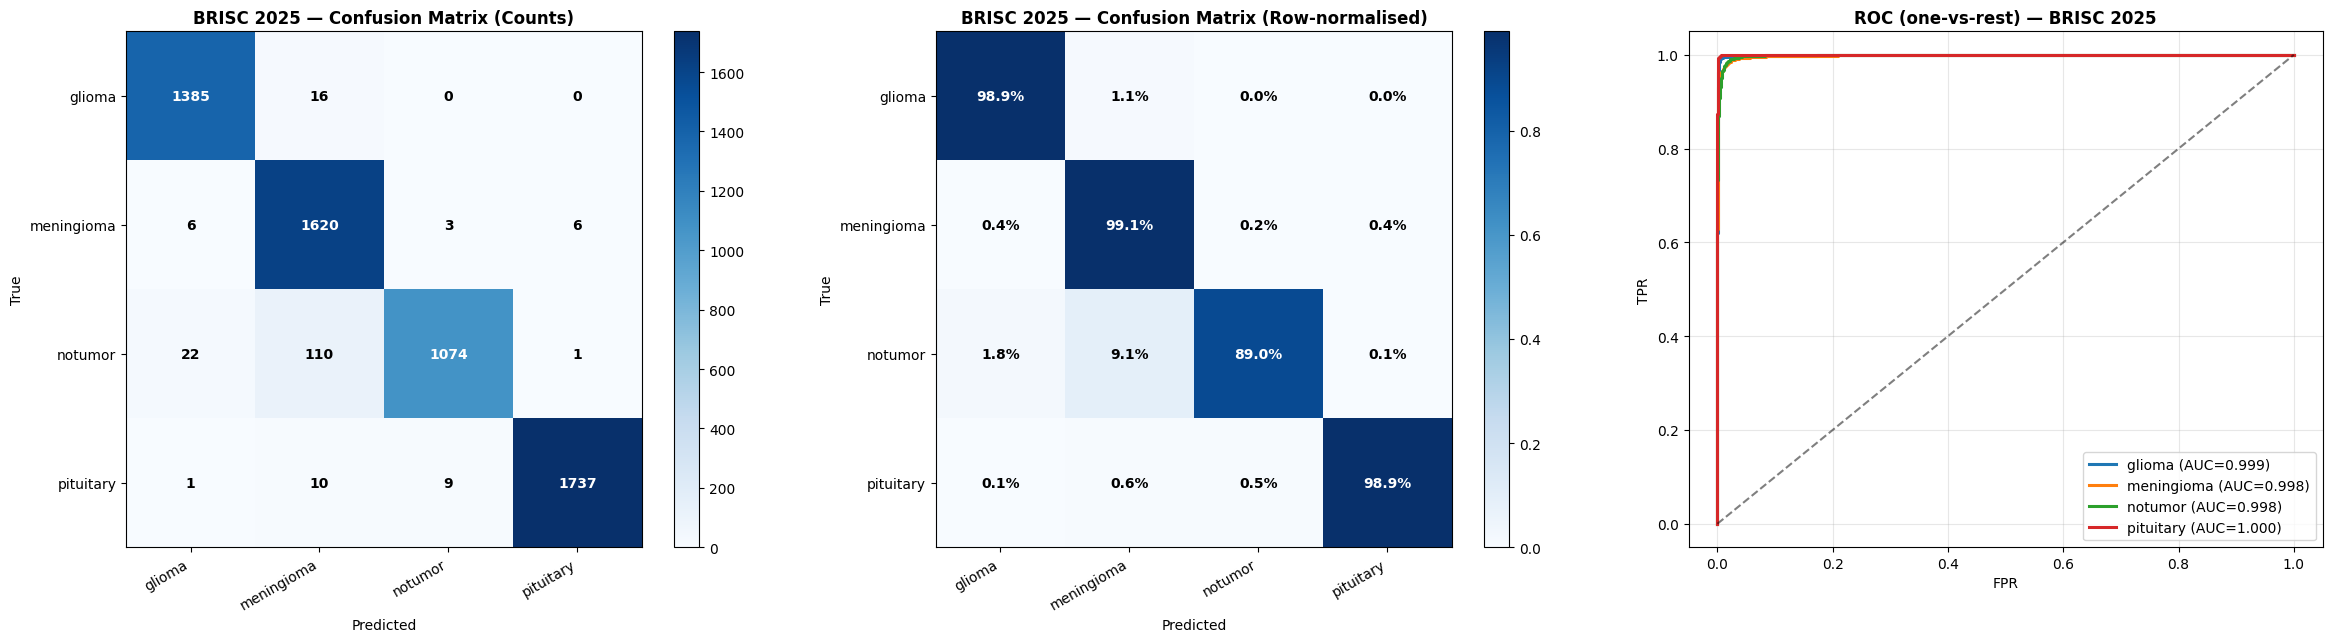

Confusion matrix (rows=true, cols=pred):
            glioma  meningioma  notumor  pituitary
glioma        1385          16        0          0
meningioma       6        1620        3          6
notumor         22         110     1074          1
pituitary        1          10        9       1737


In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
cmn = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 3, figsize=(24, 6.5))
for ax, data, title, fmt in zip(axes[:2], [cm, cmn], ['Counts', 'Row-normalised'], ['d', '.1%']):
    im = ax.imshow(data, cmap='Blues')
    ax.set_title(f'BRISC 2025 — Confusion Matrix ({title})', fontweight='bold')
    ax.set_xticks(range(4)); ax.set_yticks(range(4))
    ax.set_xticklabels(CLASSES, rotation=30, ha='right'); ax.set_yticklabels(CLASSES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    for i in range(4):
        for j in range(4):
            ax.text(j, i, format(data[i, j], fmt), ha='center', va='center',
                    color='white' if data[i, j] > data.max() / 2 else 'black', fontweight='bold')
    plt.colorbar(im, ax=ax, fraction=0.046)

yb = label_binarize(y_true, classes=range(4))
ax = axes[2]
for i, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(yb[:, i], P[:, i])
    ax.plot(fpr, tpr, lw=2.2, label=f'{c} (AUC={roc_auc_score(yb[:, i], P[:, i]):.3f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=.5)
ax.set_title('ROC (one-vs-rest) — BRISC 2025', fontweight='bold')
ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.legend(loc='lower right'); ax.grid(alpha=.3)

plt.tight_layout()
plt.savefig(f'{OUT_DIR}/brisc_confusion_roc.png', dpi=150, bbox_inches='tight')
plt.show()

print("Confusion matrix (rows=true, cols=pred):")
print(pd.DataFrame(cm, index=CLASSES, columns=CLASSES))

## Cell 10 — Bootstrap confidence intervals & AUC

In [ ]:
rng = np.random.default_rng(SEED)
N_BOOT = 1000
accs, f1s = [], []
for _ in range(N_BOOT):
    idx = rng.integers(0, len(y_true), len(y_true))
    accs.append(accuracy_score(y_true[idx], y_pred[idx]))
    f1s.append(f1_score(y_true[idx], y_pred[idx], average='macro'))

macro_f1 = f1_score(y_true, y_pred, average='macro')
macro_auc = roc_auc_score(yb, P, average='macro')
print(f"Accuracy  : {acc:.4f}  (bootstrap 95% CI {np.percentile(accs, 2.5):.4f} – {np.percentile(accs, 97.5):.4f})")
print(f"Macro-F1  : {macro_f1:.4f}  (bootstrap 95% CI {np.percentile(f1s, 2.5):.4f} – {np.percentile(f1s, 97.5):.4f})")
print(f"Macro AUC : {macro_auc:.4f}")
for i, c in enumerate(CLASSES):
    print(f"  AUC {c:12s}: {roc_auc_score(yb[:, i], P[:, i]):.4f}")

Accuracy  : 0.9693  (bootstrap 95% CI 0.9647 – 0.9733)
Macro-F1  : 0.9671  (bootstrap 95% CI 0.9621 – 0.9714)
Macro AUC : 0.9988
  AUC glioma      : 0.9988
  AUC meningioma  : 0.9983
  AUC notumor     : 0.9983
  AUC pituitary   : 0.9998


## Cell 12 — Error analysis

Misclassification pairs (true → predicted):
true_name   pred_name 
notumor     meningioma    110
            glioma         22
glioma      meningioma     16
pituitary   meningioma     10
            notumor         9
meningioma  glioma          6
            pituitary       6
            notumor         3
pituitary   glioma          1
notumor     pituitary       1

Mean confidence — correct: 0.9318 | wrong: 0.6399


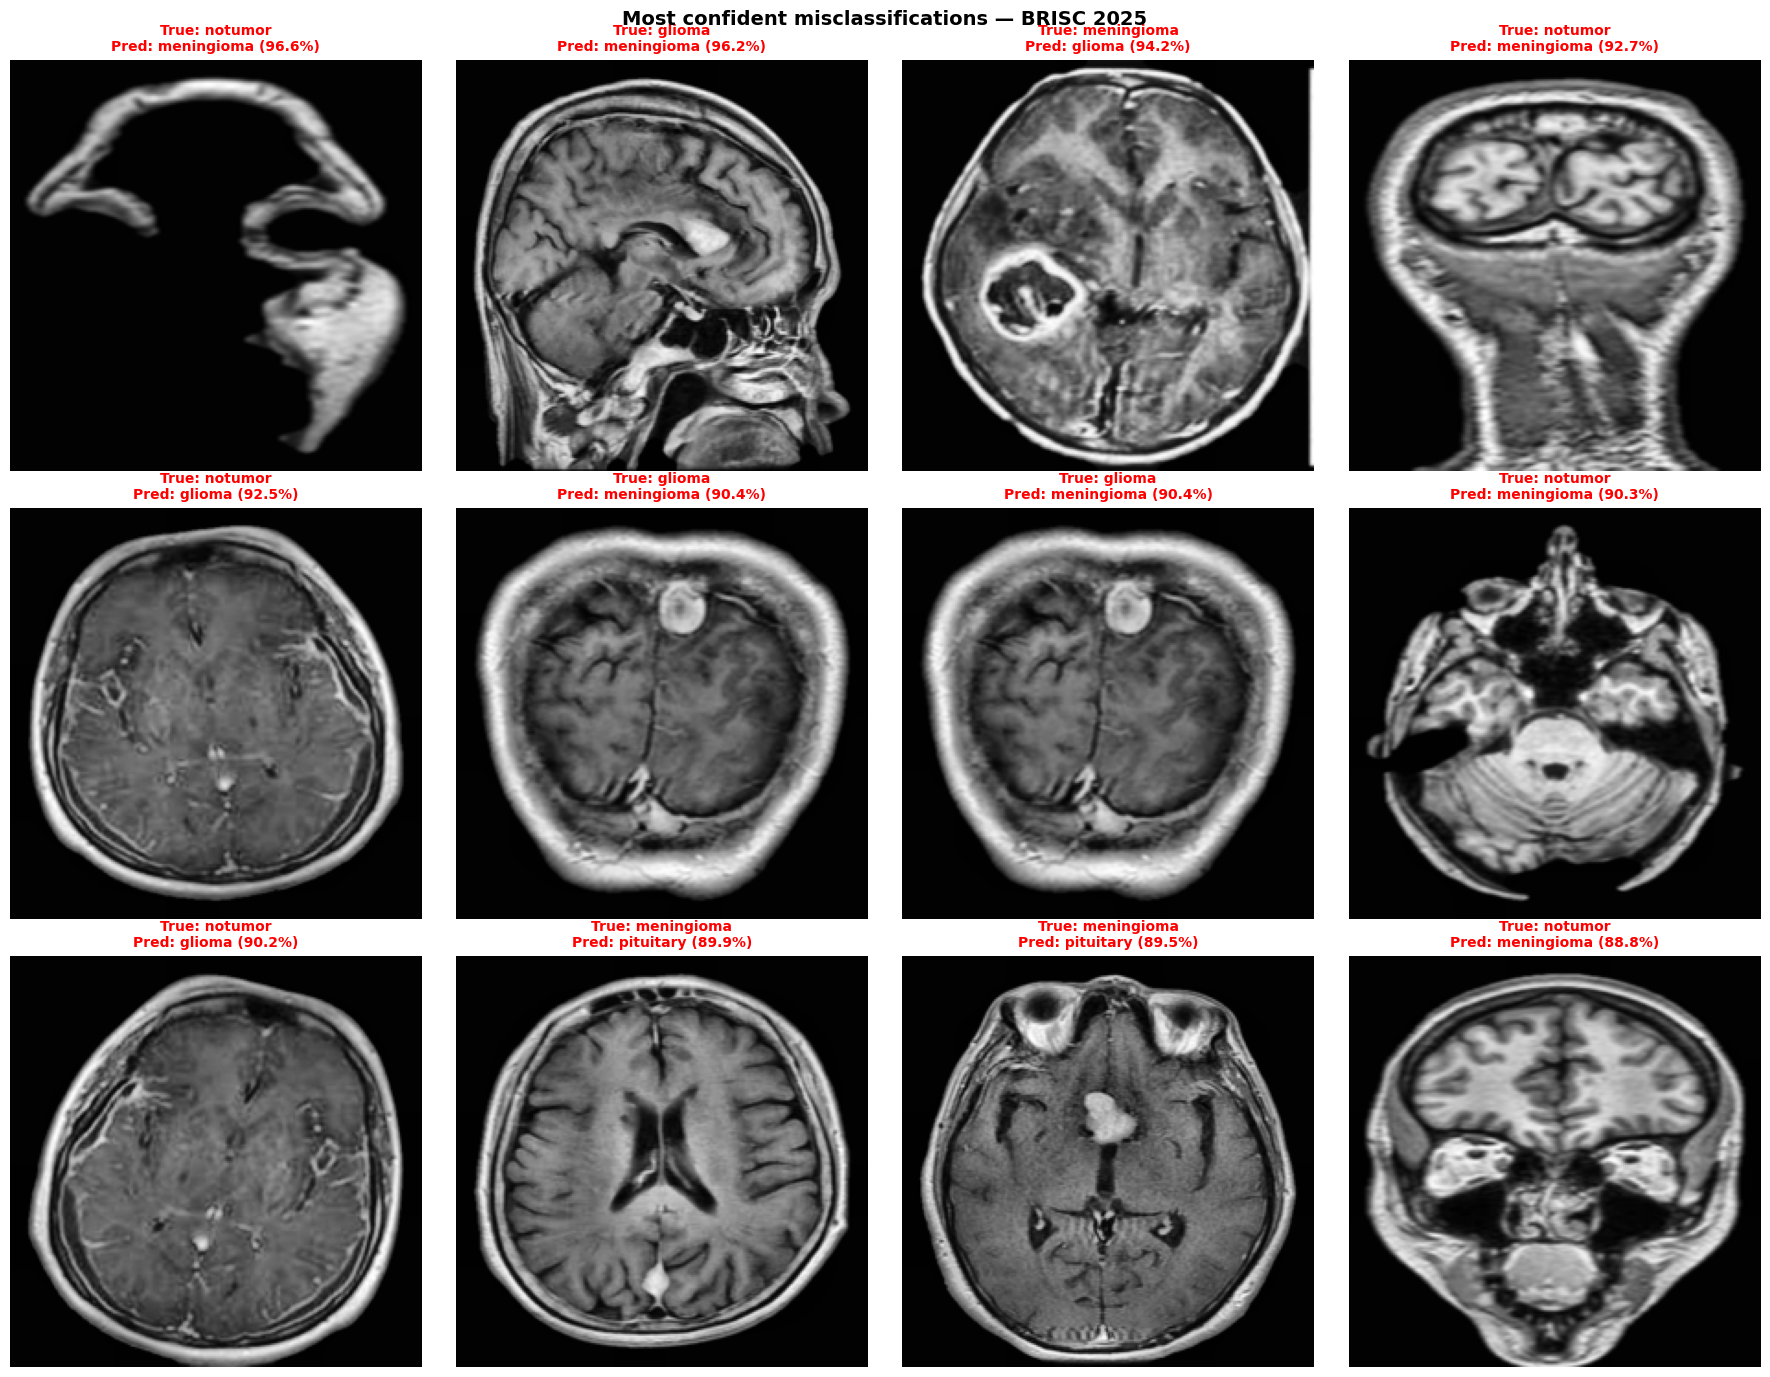

In [ ]:
err = res[res['correct'] == 0].copy()
err['true_name'] = err['y_true'].map(lambda i: CLASSES[i])
err['pred_name'] = err['y_pred'].map(lambda i: CLASSES[i])

print("Misclassification pairs (true → predicted):")
print(err.groupby(['true_name', 'pred_name']).size().sort_values(ascending=False).to_string())

print("\nMean confidence — correct:", round(res.loc[res.correct == 1, 'confidence'].mean(), 4),
      "| wrong:", round(err['confidence'].mean(), 4))

top = err.sort_values('confidence', ascending=False).head(12)
if len(top):
    fig, axes = plt.subplots(3, 4, figsize=(18, 14))
    for ax in axes.flat:
        ax.axis('off')
    for ax, (_, r) in zip(axes.flat, top.iterrows()):
        ax.imshow(pre.preprocess(r['path']))
        ax.set_title(f"True: {r['true_name']}\nPred: {r['pred_name']} ({r['confidence']:.1%})",
                     color='red', fontsize=10, fontweight='bold')
    plt.suptitle('Most confident misclassifications — BRISC 2025', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/brisc_top_errors.png', dpi=150, bbox_inches='tight')
    plt.show()